**Using Consistency loss instead of PDE residual**

Select Case (Pair of Params) --> 

Case 1 - F = 0.037 k = 0.06

Case 2 - F = 0.014 k = 0.045

Case 3 - F = 0.018 k = 0.051


In [1]:
param = 2

Specify number of spatial Data Points

In [2]:
n_data = 10000
# maximum is 10201

Specify number of Collocation Points

In [3]:
N_collocation = 20000

Specify number and inside fraction of Initial points

In [4]:
N_ic=2000
inside_fraction=0.25

# Importing Libraries

In [5]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import pandas as pd

In [6]:
# Step 1: Define problem

L = 1.0  # length of the domain
x_min, x_max = 0.0, L
y_min, y_max = 0.0, L
t_min, t_max = 0.0, 3000.0

# dimensionality
input_dim = 3   # (x, y, t)
output_dim = 1  # C only



Select the set of params

In [7]:
F1 = 0.037
k1 = 0.06

F2 = 0.014
K2 = 0.045

F3 = 0.018
K3 = 0.051

if param == 1:
    F = F1
    k = k1
elif param == 2:
    F = F2
    k = K2
elif param == 3:
    F = F3
    k = K3

Mounting Drive

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Importing Data

In [9]:
import pandas as pd

# Path to the file in Google Drive
file_path = f"/content/drive/MyDrive/gray_scott/data_{param}.txt"

# Generate column names
times = range(0, 3001, 10)

columns = ["x", "y"]

for t in times:
    columns += [f"u_{t}", f"v_{t}"]

# Read the data
df = pd.read_csv(
    file_path,
    sep=r"\s+",
    comment="%",
    header=None,
    names=columns
)

# Display the DataFrame
print(df)

              x         y  u_0           v_0  u_10          v_10  u_20  \
0      0.000000  0.000000  1.0  6.042909e-78   1.0  6.117334e-56   1.0   
1      0.001818  0.000000  1.0  1.862033e-77   1.0  6.331459e-56   1.0   
2      0.000000  0.001818  1.0  1.862033e-77   1.0  6.331459e-56   1.0   
3      0.001818  0.001818  1.0  6.159833e-77   1.0  6.553269e-56   1.0   
4      0.000000  0.003970  1.0  9.480548e-77   1.0  7.160277e-56   1.0   
...         ...       ...  ...           ...   ...           ...   ...   
10196  0.993544  0.993544  1.0  6.522265e-74   1.0  1.327692e-55   1.0   
10197  0.996030  0.990724  1.0  6.074202e-74   1.0  1.469066e-55   1.0   
10198  0.993544  0.996030  1.0  1.106633e-74   1.0  1.054667e-55   1.0   
10199  0.996030  0.993544  1.0  1.106633e-74   1.0  1.054667e-55   1.0   
10200  0.996030  0.996030  1.0  1.961192e-75   1.0  8.385713e-56   1.0   

               v_20  u_30          v_30  ...    u_2960        v_2960  \
0      2.451297e-52   1.0  6.610813e-47

In [10]:
print(df.shape)
df.head()

(10201, 604)


,x,y,u_0,v_0,u_10,v_10,u_20,v_20,u_30,v_30,...,u_2960,v_2960,u_2970,v_2970,u_2980,v_2980,u_2990,v_2990,u_3000,v_3000
0,0.000000,0.000000,1.0,6.042909e-78,1.0,6.117334e-56,1.0,2.451297e-52,1.0,6.610813e-47,...,0.996279,4.814783e-08,0.995527,1.231841e-07,0.994352,3.079850e-07,0.992603,7.492718e-07,0.990092,0.000002
1,0.001818,0.000000,1.0,1.862033e-77,1.0,6.331459e-56,1.0,2.533997e-52,1.0,6.790530e-47,...,0.996275,4.873743e-08,0.995521,1.246759e-07,0.994343,3.116657e-07,0.992590,7.580838e-07,0.990074,0.000002
2,0.000000,0.001818,1.0,1.862033e-77,1.0,6.331459e-56,1.0,2.533997e-52,1.0,6.790530e-47,...,0.996275,4.873743e-08,0.995521,1.246759e-07,0.994343,3.116657e-07,0.992590,7.580838e-07,0.990074,0.000002
3,0.001818,0.001818,1.0,6.159833e-77,1.0,6.553269e-56,1.0,2.619559e-52,1.0,6.975282e-47,...,0.996270,4.932977e-08,0.995514,1.261747e-07,0.994334,3.153640e-07,0.992577,7.669380e-07,0.990056,0.000002
4,0.000000,0.003970,1.0,9.480548e-77,1.0,7.160277e-56,1.0,2.853789e-52,1.0,7.481967e-47,...,0.996258,5.099403e-08,0.995496,1.303839e-07,0.994308,3.257453e-07,0.992542,7.917802e-07,0.990006,0.000002


Shifting to GPU (if available)

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Using device: cpu


# Sampling Points

### Sampling Data

Sampling Sparse Data from Comsol Data

In [12]:
# Separate u and v columns
u_df = df[["x", "y"] + [col for col in df.columns if col.startswith("u_")]]
v_df = df[["x", "y"] + [col for col in df.columns if col.startswith("v_")]]

# Randomly sample 1000 data points from each


u_sample = u_df.sample(n=n_data, random_state=42)
v_sample = v_df.sample(n=n_data, random_state=42)

print("u_df shape:", u_df.shape)
print("v_df shape:", v_df.shape)

print("u_sample shape:", u_sample.shape)
print("v_sample shape:", v_sample.shape)

u_df shape: (10201, 303)
v_df shape: (10201, 303)
u_sample shape: (10000, 303)
v_sample shape: (10000, 303)


In [13]:
u_sample.head()

,x,y,u_0,u_10,u_20,u_30,u_40,u_50,u_60,u_70,...,u_2910,u_2920,u_2930,u_2940,u_2950,u_2960,u_2970,u_2980,u_2990,u_3000
5135,0.763673,0.188312,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.347218,0.336555,0.332715,0.334873,0.342125,0.353633,0.368632,0.386414,0.406315,0.427689
7921,0.993544,0.223822,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.283976,0.239368,0.220853,0.219258,0.229107,0.247133,0.271298,0.300202,0.332910,0.368672
1087,0.108312,0.015918,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.981821,0.975789,0.966956,0.954292,0.936436,0.911744,0.878299,0.833932,0.776486,0.704100
4826,0.211651,0.696141,1.0,1.0,1.0,1.0,1.0,1.0,0.999998,0.999995,...,0.326610,0.338246,0.348952,0.358258,0.365628,0.370514,0.372418,0.371001,0.366202,0.358296
10060,0.984082,0.944156,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.995277,0.994962,0.994296,0.993153,0.991345,0.988623,0.984660,0.979040,0.971252,0.960699


### Sampling Collocation Points

!! Although the code here is not being used in the training loop, the consistency loss function samples collocation points after each iteration.

In [14]:
# Domain limits
x_min, x_max = df["x"].min(), df["x"].max()
y_min, y_max = df["y"].min(), df["y"].max()
t_min, t_max = 0, 3000

# Random collocation points
x_col = np.random.uniform(x_min, x_max, N_collocation)
y_col = np.random.uniform(y_min, y_max, N_collocation)
t_col = np.random.uniform(t_min, t_max, N_collocation)

# Put them into a dataframe
collocation_df = pd.DataFrame({
    "x": x_col,
    "y": y_col,
    "t": t_col
})


In [15]:
print(collocation_df.shape)
collocation_df.head()

(20000, 3)


,x,y,t
0,0.855405,0.277886,1658.641857
1,0.585203,0.221839,42.861915
2,0.553371,0.711522,2427.510006
3,0.247540,0.243895,2803.898619
4,0.697239,0.269216,2460.868116


In [16]:
def sample_collocation_points(N_col, x_min, x_max, y_min, y_max, t_min, t_max,device="cuda"):
    x = torch.rand(N_col, 1, device=device) * (x_max - x_min) + x_min
    y = torch.rand(N_col, 1, device=device) * (y_max - y_min) + y_min
    t = torch.rand(N_col, 1, device=device) * (t_max - t_min) + t_min
    return torch.cat([x, y, t], dim=1)

Defining Gradients

In [17]:
def gradients(C, x):
    return torch.autograd.grad(
        C,
        x,
        grad_outputs=torch.ones_like(C),
        create_graph=True,
        retain_graph=True
    )[0]

### Sampling Initial Points

In [18]:
def sample_initial_points(
    N_ic,
    x_min, x_max,
    y_min, y_max,
    t_min,
    inside_fraction=0.25,
    device="cuda"
):
    """
    Samples points at t = t_min.

    inside_fraction:
        Fraction of points sampled inside
        0.45 <= x <= 0.55 and 0.45 <= y <= 0.55
    """

    N_inside = int(N_ic * inside_fraction)
    N_outside = N_ic - N_inside

    # ---------------------------------------------
    # Sample points inside the central square
    # ---------------------------------------------

    x_inside = torch.rand(N_inside, 1, device=device) * 0.10 + 0.45
    y_inside = torch.rand(N_inside, 1, device=device) * 0.10 + 0.45

    # ---------------------------------------------
    # Sample points outside the central square
    # ---------------------------------------------

    x_outside_list = []
    y_outside_list = []

    while sum(len(x) for x in x_outside_list) < N_outside:

        N_remaining = N_outside - sum(
            len(x) for x in x_outside_list
        )

        x_new = (
            torch.rand(N_remaining, 1, device=device)
            * (x_max - x_min)
            + x_min
        )

        y_new = (
            torch.rand(N_remaining, 1, device=device)
            * (y_max - y_min)
            + y_min
        )

        outside_mask = ~(
            (x_new >= 0.45) & (x_new <= 0.55) &
            (y_new >= 0.45) & (y_new <= 0.55)
        )

        x_outside_list.append(x_new[outside_mask].reshape(-1, 1))
        y_outside_list.append(y_new[outside_mask].reshape(-1, 1))

    x_outside = torch.cat(x_outside_list)[:N_outside]
    y_outside = torch.cat(y_outside_list)[:N_outside]

    # ---------------------------------------------
    # Combine points
    # ---------------------------------------------

    x = torch.cat([x_inside, x_outside], dim=0)
    y = torch.cat([y_inside, y_outside], dim=0)

    # All points are at t = t_min
    t = torch.full_like(x, t_min, device=device)

    # ---------------------------------------------
    # Target values
    # ---------------------------------------------

    u_true = torch.cat([
        torch.full((N_inside, 1), 0.5, device=device),
        torch.full((N_outside, 1), 1.0, device=device)
    ])

    v_true = torch.cat([
        torch.full((N_inside, 1), 0.25, device=device),
        torch.full((N_outside, 1), 0.0, device=device)
    ])

    return x, y, t, u_true, v_true

In [19]:
x_ic, y_ic, t_ic, u_ic, v_ic = sample_initial_points(
    N_ic,
    x_min=x_min,
    x_max=x_max,
    y_min=y_min,
    y_max=y_max,
    t_min=t_min,
    inside_fraction=inside_fraction,
    device=device
)

### Sample Boundary Points

In [20]:
def sample_boundary_points(
    N_bc,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max,
    device="cuda"
):
    """
    Randomly samples points on all four boundaries
    over the full time domain.

    Returns:
        x_bc, y_bc, t_bc
    """

    # Divide points approximately equally among 4 boundaries
    N_left = N_bc // 4
    N_right = N_bc // 4
    N_bottom = N_bc // 4
    N_top = N_bc - N_left - N_right - N_bottom

    # ---------------------------------------------
    # Left boundary: x = x_min
    # ---------------------------------------------

    x_left = torch.full((N_left, 1), x_min, device=device)
    y_left = torch.rand(N_left, 1, device=device) * (y_max - y_min) + y_min
    t_left = torch.rand(N_left, 1, device=device) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Right boundary: x = x_max
    # ---------------------------------------------

    x_right = torch.full((N_right, 1), x_max, device=device)
    y_right = torch.rand(N_right, 1, device=device) * (y_max - y_min) + y_min
    t_right = torch.rand(N_right, 1, device=device) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Bottom boundary: y = y_min
    # ---------------------------------------------

    x_bottom = torch.rand(N_bottom, 1, device=device) * (x_max - x_min) + x_min
    y_bottom = torch.full((N_bottom, 1), y_min, device=device)
    t_bottom = torch.rand(N_bottom, 1, device=device) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Top boundary: y = y_max
    # ---------------------------------------------

    x_top = torch.rand(N_top, 1, device=device) * (x_max - x_min) + x_min
    y_top = torch.full((N_top, 1), y_max, device=device)
    t_top = torch.rand(N_top, 1, device=device) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Combine
    # ---------------------------------------------

    x_bc = torch.cat([
        x_left,
        x_right,
        x_bottom,
        x_top
    ], dim=0)

    y_bc = torch.cat([
        y_left,
        y_right,
        y_bottom,
        y_top
    ], dim=0)

    t_bc = torch.cat([
        t_left,
        t_right,
        t_bottom,
        t_top
    ], dim=0)

    return x_bc, y_bc, t_bc

In [21]:
x_bc, y_bc, t_bc = sample_boundary_points(
    1000,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max,
    device=device
)

# Defining model for u(x,y,t) and v(x,y,t)

In [22]:
class u_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self, X):
        # xt = torch.cat([x, y, t], dim=-1)
        return self.network(X)


In [23]:
class v_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self, X):
        # xt = torch.cat([x, y, t], dim=-1)
        return self.network(X)


### Diffusion Coefficients

In [24]:
D_SCALE = 1e-5   # characteristic magnitude of the diffusion coefficients

class Du_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,1)
        )

    def forward(self, X):
        # network output is O(1); scale it and keep it positive
        return D_SCALE * torch.nn.functional.softplus(self.network(X))


class Dv_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.Dv_raw = nn.Parameter(torch.tensor(1.0))   # O(1) parameter -> Dv about 1.3e-5 at init

    def value(self):
        return D_SCALE * torch.nn.functional.softplus(self.Dv_raw)

    def forward(self, X):
        return self.value() * torch.ones_like(X[:, 0:1])   # shape (N,1)

# Defining Different Losses

### Data Loss

In [25]:
times = np.arange(0, 3001, 10)

# u data
x_u = np.repeat(u_sample["x"].values, len(times))
y_u = np.repeat(u_sample["y"].values, len(times))
t_u = np.tile(times, len(u_sample))

u_true = u_sample[
    [f"u_{t}" for t in times]
].values.flatten()

# v data
x_v = np.repeat(v_sample["x"].values, len(times))
y_v = np.repeat(v_sample["y"].values, len(times))
t_v = np.tile(times, len(v_sample))

v_true = v_sample[
    [f"v_{t}" for t in times]
].values.flatten()

In [26]:
X_u = torch.tensor(
    np.column_stack([x_u, y_u, t_u]),
    dtype=torch.float32
)

U_true = torch.tensor(
    u_true.reshape(-1, 1),
    dtype=torch.float32
)

X_v = torch.tensor(
    np.column_stack([x_v, y_v, t_v]),
    dtype=torch.float32
)

V_true = torch.tensor(
    v_true.reshape(-1, 1),
    dtype=torch.float32
)

Take to GPU iv available

In [27]:
X_u, U_true = X_u.to(device), U_true.to(device)
X_v, V_true = X_v.to(device), V_true.to(device)

In [28]:
def data_loss(u_net,
        v_net,
        X_u,
        U_true,
        X_v,
        V_true,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max):

    # Normalize inputs
    X_u_norm = X_u.clone()
    X_v_norm = X_v.clone()

    X_u_norm[:, 0] = normalize(X_u[:, 0], x_min, x_max)
    X_u_norm[:, 1] = normalize(X_u[:, 1], y_min, y_max)
    X_u_norm[:, 2] = normalize(X_u[:, 2], t_min, t_max)

    X_v_norm[:, 0] = normalize(X_v[:, 0], x_min, x_max)
    X_v_norm[:, 1] = normalize(X_v[:, 1], y_min, y_max)
    X_v_norm[:, 2] = normalize(X_v[:, 2], t_min, t_max)

    # Predictions
    U_pred = u_net(X_u_norm)
    V_pred = v_net(X_v_norm)

    # MSE
    loss_u = torch.mean((U_pred - U_true) ** 2)
    loss_v = torch.mean((V_pred - V_true) ** 2)

    return loss_u + loss_v

### PDE consistency Loss

In [29]:
def normalize(x, xmin, xmax):
    return 2.0 * (x - xmin) / (xmax - xmin) - 1.0

In [30]:
def make_D_fns(Du_nn, Dv_nn):
    def Du_fn(x, y):
        return Du_nn(torch.cat([normalize(x, x_min, x_max), normalize(y, y_min, y_max)], dim=1))
    def Dv_fn(x, y):
        return Dv_nn(torch.cat([normalize(x, x_min, x_max), normalize(y, y_min, y_max)], dim=1))
    return Du_fn, Dv_fn

def div_flux(D, f, x, y):
    """div(D grad f) in physical coordinates."""
    f_x, f_y = torch.autograd.grad(f, [x, y], torch.ones_like(f), create_graph=True)
    qx, qy = D * f_x, D * f_y
    dqx = torch.autograd.grad(qx, x, torch.ones_like(qx), create_graph=True)[0]
    dqy = torch.autograd.grad(qy, y, torch.ones_like(qy), create_graph=True)[0]
    return dqx + dqy

def be_consistency_loss(u_nn, v_nn, Du_fn, Dv_fn, F, k, N, dt,
                        sigma_u, sigma_v, t_lo=None):
    t_lo = t_min if t_lo is None else t_lo
    x = (torch.rand(N, 1, device=device) * float(x_max - x_min) + float(x_min)).requires_grad_(True)
    y = (torch.rand(N, 1, device=device) * float(y_max - y_min) + float(y_min)).requires_grad_(True)
    t0 = torch.rand(N, 1, device=device) * float(t_max - dt - t_lo) + float(t_lo)
    t1 = t0 + dt

    def inp(t):
        return torch.cat([normalize(x, x_min, x_max),
                          normalize(y, y_min, y_max),
                          normalize(t, t_min, t_max)], dim=1)

    X0, X1 = inp(t0), inp(t1)
    u0, v0 = u_nn(X0), v_nn(X0)
    u1, v1 = u_nn(X1), v_nn(X1)

    Du, Dv = Du_fn(x, y), Dv_fn(x, y)

    # Gray-Scott right-hand sides, evaluated at t+dt (backward Euler)
    div_u, div_v = div_flux(Du, u1, x, y), div_flux(Dv, v1, x, y)
    R_u = div_u - u1 * v1**2 + F * (1 - u1)
    R_v = div_v + u1 * v1**2 - (F + k) * v1

    u_pi = u1 - dt * R_u          # predicted u at time t
    v_pi = v1 - dt * R_v

    loss_u = torch.mean(((u_pi - u0) / sigma_u) ** 2)
    loss_v = torch.mean(((v_pi - v0) / sigma_v) ** 2)
    return div_u.mean(),div_v.mean(),loss_u,loss_v,loss_u + loss_v


# def be_consistency_loss(
#     u_nn, v_nn,
#     Du_fn, Dv_fn,
#     F, k, N, dt,
#     sigma_u, sigma_v,
#     t_lo=None,
#     adaptive=False,
#     N_candidates=50000,
#     adaptive_fraction=0.7,
#     alpha=0.5
# ):
#     """
#     Backward-Euler consistency loss with optional adaptive sampling.

#     adaptive_fraction:
#         Fraction of N sampled adaptively.
#         Remaining fraction is sampled uniformly.

#     alpha:
#         Controls how strongly high-loss points are preferred.
#         alpha = 0.5 is a good starting point.
#     """

#     t_lo = t_min if t_lo is None else t_lo

#     # ---------------------------------------------------------
#     # 1. Generate candidate points
#     # ---------------------------------------------------------

#     if adaptive:

#         x_c = (
#             torch.rand(N_candidates, 1, device=device)
#             * float(x_max - x_min) + float(x_min)
#         ).requires_grad_(True)

#         y_c = (
#             torch.rand(N_candidates, 1, device=device)
#             * float(y_max - y_min) + float(y_min)
#         ).requires_grad_(True)

#         t0_c = (
#             torch.rand(N_candidates, 1, device=device)
#             * float(t_max - dt - t_lo) + float(t_lo)
#         )

#         t1_c = t0_c + dt

#         def inp_candidate(t):
#             return torch.cat([
#                 normalize(x_c, x_min, x_max),
#                 normalize(y_c, y_min, y_max),
#                 normalize(t, t_min, t_max)
#             ], dim=1)

#         X0_c = inp_candidate(t0_c)
#         X1_c = inp_candidate(t1_c)

#         u0_c, v0_c = u_nn(X0_c), v_nn(X0_c)
#         u1_c, v1_c = u_nn(X1_c), v_nn(X1_c)

#         Du_c = Du_fn(x_c, y_c)
#         Dv_c = Dv_fn(x_c, y_c)

#         div_u_c = div_flux(Du_c, u1_c, x_c, y_c)
#         div_v_c = div_flux(Dv_c, v1_c, x_c, y_c)

#         R_u_c = (
#             div_u_c
#             - u1_c * v1_c**2
#             + F * (1 - u1_c)
#         )

#         R_v_c = (
#             div_v_c
#             + u1_c * v1_c**2
#             - (F + k) * v1_c
#         )

#         u_pi_c = u1_c - dt * R_u_c
#         v_pi_c = v1_c - dt * R_v_c

#         point_loss_u_c = ((u_pi_c - u0_c) / sigma_u) ** 2
#         point_loss_v_c = ((v_pi_c - v0_c) / sigma_v) ** 2

#         point_loss_c = point_loss_u_c + point_loss_v_c

#         # ---------------------------------------------------------
#         # 2. Convert losses to sampling probabilities
#         # ---------------------------------------------------------

#         weights = (point_loss_c.detach().flatten() + 1e-8) ** alpha

#         weights = weights / weights.sum()

#         N_adaptive = int(N * adaptive_fraction)
#         N_uniform = N - N_adaptive

#         # ---------------------------------------------------------
#         # 3. Sample high-loss points
#         # ---------------------------------------------------------

#         idx = torch.multinomial(
#             weights,
#             N_adaptive,
#             replacement=False
#         )

#         x_adapt = x_c.detach()[idx]
#         y_adapt = y_c.detach()[idx]
#         t0_adapt = t0_c.detach()[idx]

#         # ---------------------------------------------------------
#         # 4. Add uniformly sampled points
#         # ---------------------------------------------------------

#         x_uniform = (
#             torch.rand(N_uniform, 1, device=device)
#             * float(x_max - x_min) + float(x_min)
#         )

#         y_uniform = (
#             torch.rand(N_uniform, 1, device=device)
#             * float(y_max - y_min) + float(y_min)
#         )

#         t0_uniform = (
#             torch.rand(N_uniform, 1, device=device)
#             * float(t_max - dt - t_lo) + float(t_lo)
#         )

#         # ---------------------------------------------------------
#         # 5. Combine adaptive + uniform samples
#         # ---------------------------------------------------------

#         x = torch.cat([x_adapt, x_uniform], dim=0).requires_grad_(True)
#         y = torch.cat([y_adapt, y_uniform], dim=0).requires_grad_(True)
#         t0 = torch.cat([t0_adapt, t0_uniform], dim=0)

#     # ---------------------------------------------------------
#     # Original uniform sampling
#     # ---------------------------------------------------------

#     else:

#         x = (
#             torch.rand(N, 1, device=device)
#             * float(x_max - x_min) + float(x_min)
#         ).requires_grad_(True)

#         y = (
#             torch.rand(N, 1, device=device)
#             * float(y_max - y_min) + float(y_min)
#         ).requires_grad_(True)

#         t0 = (
#             torch.rand(N, 1, device=device)
#             * float(t_max - dt - t_lo) + float(t_lo)
#         )

#     # ---------------------------------------------------------
#     # Original BE calculation
#     # ---------------------------------------------------------

#     t1 = t0 + dt

#     def inp(t):
#         return torch.cat([
#             normalize(x, x_min, x_max),
#             normalize(y, y_min, y_max),
#             normalize(t, t_min, t_max)
#         ], dim=1)

#     X0, X1 = inp(t0), inp(t1)

#     u0, v0 = u_nn(X0), v_nn(X0)
#     u1, v1 = u_nn(X1), v_nn(X1)

#     Du, Dv = Du_fn(x, y), Dv_fn(x, y)

#     div_u = div_flux(Du, u1, x, y)
#     div_v = div_flux(Dv, v1, x, y)

#     R_u = div_u - u1 * v1**2 + F * (1 - u1)
#     R_v = div_v + u1 * v1**2 - (F + k) * v1

#     u_pi = u1 - dt * R_u
#     v_pi = v1 - dt * R_v

#     point_loss_u = ((u_pi - u0) / sigma_u) ** 2
#     point_loss_v = ((v_pi - v0) / sigma_v) ** 2

#     loss_u = torch.mean(point_loss_u)
#     loss_v = torch.mean(point_loss_v)

#     L = loss_u + loss_v

#     return (
#         div_u.mean(),
#         div_v.mean(),
#         loss_u,
#         loss_v,
#         L
#     )
sigma_u = U_true.std().item()
sigma_v = V_true.std().item()
dt_be = 20.0        # physical time units; data spacing is 10
t_lo_be = 500.0     # skip early times where the fields are almost flat (no information on D)

Ploting consistency loss heatmap

In [31]:
def plot_be_loss_heatmaps(
    x, y,
    loss_u,
    loss_v,
    step,
    threshold=0.5,
    min_size=5,
    max_size=150,
    title_prefix="BE consistency loss"
):
    """
    Plot spatial scatter heatmaps of the pointwise backward-Euler
    consistency losses.

    Points with loss < threshold are not plotted.
    Marker size is scaled according to the loss.
    """

    x = x.detach().cpu().numpy().ravel()
    y = y.detach().cpu().numpy().ravel()

    loss_u = loss_u.detach().cpu().numpy().ravel()
    loss_v = loss_v.detach().cpu().numpy().ravel()

    loss_total = loss_u + loss_v

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 5),
        constrained_layout=True
    )

    plots = [
        (loss_u, r"$L_u$"),
        (loss_v, r"$L_v$"),
        (loss_total, r"$L_u + L_v$")
    ]

    for ax, (loss, title) in zip(axes, plots):

        # -------------------------------------------------
        # Keep only points above the threshold
        # -------------------------------------------------
        mask = loss >= threshold

        x_plot = x[mask]
        y_plot = y[mask]
        loss_plot = loss[mask]

        if len(loss_plot) == 0:
            ax.set_title(f"{title}\n(no points ≥ {threshold})")
            ax.set_xlabel("x")
            ax.set_ylabel("y")
            continue

        # -------------------------------------------------
        # Scale marker size according to loss
        # -------------------------------------------------

        loss_min = loss_plot.min()
        loss_max = loss_plot.max()

        if loss_max > loss_min:
            sizes = min_size + (
                (loss_plot - loss_min) /
                (loss_max - loss_min)
            ) * (max_size - min_size)
        else:
            sizes = np.full_like(
                loss_plot,
                (min_size + max_size) / 2
            )

        # -------------------------------------------------
        # Scatter heatmap
        # -------------------------------------------------

        sc = ax.scatter(
            x_plot,
            y_plot,
            c=loss_plot,
            s=sizes,
            cmap="viridis",
            alpha=0.8,
            edgecolors="none",
            rasterized=True
        )

        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_title(
            f"{title}\n"
            f"{len(loss_plot)}/{len(loss)} points"
        )

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        ax.set_aspect("equal")

        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label("Pointwise BE loss")

    fig.suptitle(
        f"{title_prefix} — step {step}",
        fontsize=15
    )

    plt.show()

### Initial Condition Losses

In [32]:
def initial_condition_loss_pretraining(
    u_net,
    x, y, t,
    u_true,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max
):

    # Normalize inputs
    x_n = normalize(x, x_min, x_max)
    y_n = normalize(y, y_min, y_max)
    t_n = normalize(t, t_min, t_max)

    X_ic = torch.cat([x_n, y_n, t_n], dim=1)

    # Predictions
    u_pred = u_net(X_ic)
    # v_pred = v_net(X_ic)

    # Losses
    loss_u = torch.mean((u_pred - u_true) ** 2)
    # loss_v = torch.mean((v_pred - v_true) ** 2)

    loss_ic = loss_u
    # loss_ic = loss_u + loss_v

    return loss_ic

In [33]:
for i in range(len(x_ic)):
    print(f"x: {x_ic[i].item():.4f}, y: {y_ic[i].item():.4f}, t: {t_ic[i].item():.4f}, u_true: {u_ic[i].item():.4f}, v_true: {v_ic[i].item():.4f}")

x: 0.5161, y: 0.4992, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.5278, y: 0.4566, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.4583, y: 0.5155, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.4723, y: 0.4877, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.4639, y: 0.4859, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.4753, y: 0.5289, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.4670, y: 0.5016, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.5299, y: 0.5465, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.4700, y: 0.4969, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.5077, y: 0.5060, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.5024, y: 0.4815, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.4766, y: 0.4988, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.4729, y: 0.4707, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.5030, y: 0.4646, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.4817, y: 0.4571, t: 0.0000, u_true: 0.5000, v_true: 0.2500
x: 0.4821, y: 0.5243, t: 0.0000, u_true:

### Boundary Condition Loss

In [34]:
def boundary_condition_loss(
    u_net,
    v_net,
    x_bc, y_bc, t_bc,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max
):

    # ---------------------------------------------
    # Normalization factors
    # ---------------------------------------------

    sx = 2.0 / (x_max - x_min)
    sy = 2.0 / (y_max - y_min)

    # ---------------------------------------------
    # Normalize coordinates
    # ---------------------------------------------

    x_n = normalize(x_bc, x_min, x_max)
    y_n = normalize(y_bc, y_min, y_max)
    t_n = normalize(t_bc, t_min, t_max)

    X_bc = torch.cat([x_n, y_n, t_n], dim=1)
    X_bc.requires_grad_(True)

    # ---------------------------------------------
    # Network predictions
    # ---------------------------------------------

    u = u_net(X_bc)
    v = v_net(X_bc)

    # ---------------------------------------------
    # Gradients of u
    # ---------------------------------------------

    u_grad = torch.autograd.grad(
        u,
        X_bc,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xn = u_grad[:, 0:1]
    u_yn = u_grad[:, 1:2]

    # Convert to physical derivatives
    u_x = sx * u_xn
    u_y = sy * u_yn

    # ---------------------------------------------
    # Gradients of v
    # ---------------------------------------------

    v_grad = torch.autograd.grad(
        v,
        X_bc,
        grad_outputs=torch.ones_like(v),
        create_graph=True
    )[0]

    v_xn = v_grad[:, 0:1]
    v_yn = v_grad[:, 1:2]

    # Convert to physical derivatives
    v_x = sx * v_xn
    v_y = sy * v_yn

    # ---------------------------------------------
    # Determine which points are on which boundary
    # ---------------------------------------------

    # Points are ordered: left | right | bottom | top (see sample_boundary_points)
    q = x_bc.shape[0] // 4

    u_normal_x = torch.cat([u_x[:q],      u_x[q:2*q]])
    v_normal_x = torch.cat([v_x[:q],      v_x[q:2*q]])

    u_normal_y = torch.cat([u_y[2*q:3*q], u_y[3*q:]])
    v_normal_y = torch.cat([v_y[2*q:3*q], v_y[3*q:]])

    # ---------------------------------------------
    # Zero-flux loss
    # ---------------------------------------------

    loss_u = (
        torch.mean(u_normal_x**2)
        + torch.mean(u_normal_y**2)
    )

    loss_v = (
        torch.mean(v_normal_x**2)
        + torch.mean(v_normal_y**2)
    )

    loss_bc = loss_u + loss_v

    return loss_bc

### Aggregate Loss

In [35]:
def total_loss(
    u_net,
    v_net,
    D_net,
    Dv_net,
    F,
    k,

    # Data points
    X_u,
    U_true,
    X_v,
    V_true,

    # Initial-condition points
    x_ic,
    y_ic,
    t_ic,
    u_ic_true,
    v_ic_true,

    # Boundary-condition points
    x_bc,
    y_bc,
    t_bc,

    # Collocation points
    X_col,

    # Loss weights
    lambda_data=1.0,
    lambda_ic=1.0,
    lambda_bc=1.0,
    lambda_pde=1.0,

    # Domain
    x_min=0.0,
    x_max=1.0,
    y_min=0.0,
    y_max=1.0,
    t_min=0.0,
    t_max=3000.0
):

    # 1. Data loss
    L_data = data_loss(
        u_net,
        v_net,
        X_u,
        U_true,
        X_v,
        V_true,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # 2. Initial-condition loss
    L_ic = initial_condition_loss(
        u_net,
        v_net,
        x_ic,
        y_ic,
        t_ic,
        u_ic_true,
        v_ic_true,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # 3. Boundary-condition loss
    L_bc = boundary_condition_loss(
        u_net,
        v_net,
        x_bc,
        y_bc,
        t_bc,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # 4. PDE loss
    L_pde = be_consistency_loss(
        u_net,
        v_net,
        Du_fn,
        Dv_fn,
        F, k,
        N_col,
        dt_be,
        sigma_u,
        sigma_v,
        t_lo=t_lo_be
    )

    # Weighted total loss
    L_total = (
        lambda_data * L_data
        + lambda_ic * L_ic
        + lambda_bc * L_bc
        + lambda_pde * L_pde
    )

    return L_total, L_data, L_ic, L_bc, L_pde

# Training

## Creating instance of NNs

In [36]:
u_nn  = u_net().to(device)
v_nn  = v_net().to(device)

In [37]:
Du_nn = Du_net().to(device)
Dv_nn = Dv_net().to(device)

In [38]:
Du_fn, Dv_fn = make_D_fns(Du_nn, Dv_nn)

## Pre-Training

### Splitting Data into mini batches, defining pretraining Losses

In [39]:
import math

batch_size = 32768   # was 4096, see Fix 2
n_batches = math.ceil(X_u.shape[0] / batch_size)

def batch_iterator(X, U, V, batch_size):
    perm = torch.randperm(X.shape[0], device=X.device)
    for i in range(0, X.shape[0], batch_size):
        idx = perm[i:i + batch_size]
        yield X[idx], U[idx], V[idx]

Separate Losses for u and v

In [40]:
def pretraining_loss_u(
    u_net,
    X_batch,
    U_true_batch,
    V_true_batch,
    x_min,
    x_max,
    y_min,
    y_max,
    t_min,
    t_max
):

    # Normalize inputs
    x_n = normalize(X_batch[:, 0:1], x_min, x_max)
    y_n = normalize(X_batch[:, 1:2], y_min, y_max)
    t_n = normalize(X_batch[:, 2:3], t_min, t_max)

    X_norm = torch.cat([x_n, y_n, t_n], dim=1)

    # Predictions
    u_pred = u_net(X_norm)
    # v_pred = v_net(X_norm)

    # Data losses
    loss_u = torch.mean((u_pred - U_true_batch) ** 2)
    # loss_v = torch.mean((v_pred - V_true_batch) ** 2)

    # Total pre-training loss
    # loss = loss_u + loss_v

    return loss_u

In [41]:
def pretraining_loss_v(
    v_net,
    X_batch,
    U_true_batch,
    V_true_batch,
    x_min,
    x_max,
    y_min,
    y_max,
    t_min,
    t_max
):

    # Normalize inputs
    x_n = normalize(X_batch[:, 0:1], x_min, x_max)
    y_n = normalize(X_batch[:, 1:2], y_min, y_max)
    t_n = normalize(X_batch[:, 2:3], t_min, t_max)

    X_norm = torch.cat([x_n, y_n, t_n], dim=1)

    # Predictions
    # u_pred = u_net(X_norm)
    v_pred = v_net(X_norm)

    # Data losses
    # loss_u = torch.mean((u_pred - U_true_batch) ** 2)
    loss_v = torch.mean((v_pred - V_true_batch) ** 2)

    # Total pre-training loss
    # loss = loss_u + loss_v

    return loss_v

### Specify Hyperparams for pre-training

In [43]:
pre_batch_size = 16384      # small batches = many steps (pre-training is cheap)
pre_epochs = 5
n_pre = math.ceil(X_u.shape[0] / pre_batch_size)

### Training Loop for u

In [44]:
optimizer_pretrain_u = torch.optim.Adam(
    list(u_nn.parameters()), lr=2e-3
)
scheduler_u = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_pretrain_u, T_max=pre_epochs, eta_min=1e-5
)

for epoch in range(pre_epochs):
    tot_u = 0.0
    # tot_v = 0.0

    for X_batch, U_b, V_b in batch_iterator(X_u, U_true, V_true, pre_batch_size):
        loss_u = pretraining_loss_u(
            u_nn, X_batch, U_b, V_b,
            x_min, x_max, y_min, y_max, t_min, t_max
        )
        optimizer_pretrain_u.zero_grad()
        loss_u.backward()

        optimizer_pretrain_u.step()
        tot_u += loss_u.detach()


    scheduler_u.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{pre_epochs} | "
              f"u MSE {tot_u.item()/n_pre:.3e} (var {U_true.var().item():.2e}) ")




# optimizer_pretrain_u = torch.optim.Adam(
#     list(u_nn.parameters()), lr=2e-3
# )
# scheduler_u = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer_pretrain_u, T_max=pre_epochs, eta_min=1e-5
# )

# lambda_ic = 1.0  # Weight for initial condition loss

# for epoch in range(pre_epochs):
#     tot_u = 0.0
#     tot_ic = 0.0

#     for X_batch, U_b, V_b in batch_iterator(
#         X_u, U_true, V_true, pre_batch_size
#     ):
#         # Original pretraining loss
#         loss_u = pretraining_loss_u(
#             u_nn, X_batch, U_b, V_b,
#             x_min, x_max, y_min, y_max, t_min, t_max
#         )

#         # Initial condition loss using your sampled points
#         loss_ic = initial_condition_loss_pretraining(
#             u_nn,
#             x_ic, y_ic, t_ic, u_ic,
#             x_min, x_max, y_min, y_max, t_min, t_max
#         )

#         # Combined loss
#         loss = loss_u + lambda_ic * loss_ic

#         optimizer_pretrain_u.zero_grad()
#         loss.backward()
#         optimizer_pretrain_u.step()

#         tot_u += loss_u.detach()
#         tot_ic += loss_ic.detach()

#     scheduler_u.step()

#     if (epoch + 1) % 20 == 0:
#         print(
#             f"Epoch {epoch+1}/{pre_epochs} | "
#             f"u MSE {tot_u.item()/n_pre:.3e} "
#             f"(var {U_true.var().item():.2e}) | "
#             f"IC Loss {tot_ic.item()/len(X_u):.3e}"
#         )

### Training Loop for v

In [45]:
optimizer_pretrain_v = torch.optim.Adam(
    list(v_nn.parameters()), lr=2e-3
)
scheduler_v = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_pretrain_v, T_max=pre_epochs, eta_min=1e-5
)

for epoch in range(pre_epochs):

    tot_v = 0.0

    for X_batch, U_b, V_b in batch_iterator(X_u, U_true, V_true, pre_batch_size):
        loss_v = pretraining_loss_v(
            v_nn, X_batch, U_b, V_b,
            x_min, x_max, y_min, y_max, t_min, t_max
        )
        optimizer_pretrain_v.zero_grad()
        loss_v.backward()
        optimizer_pretrain_v.step()
        tot_v += loss_v.detach()

    scheduler_v.step()

    if (epoch + 1) % 1 == 0:
        print(f"Epoch {epoch+1}/{pre_epochs} | "
              f"v MSE {tot_v.item()/n_pre:.3e} (var {V_true.var().item():.2e})")

Epoch 1/5 | v MSE 1.232e-02 (var 1.64e-02)
Epoch 2/5 | v MSE 1.005e-02 (var 1.64e-02)
Epoch 3/5 | v MSE 9.891e-03 (var 1.64e-02)
Epoch 4/5 | v MSE 9.743e-03 (var 1.64e-02)
Epoch 5/5 | v MSE 9.670e-03 (var 1.64e-02)


### Saving the pre-trained weights

In [ ]:
import os
from google.colab import drive
# drive.mount("/content/drive")   # skip if already mounted

save_dir = f"/content/drive/MyDrive/gray_scott/checkpoints_{param}/pretrained"
os.makedirs(save_dir, exist_ok=True)
pretrain_path = os.path.join(save_dir, f"uv_{n_data}_spatial_points.pt")

torch.save({
    "u_nn": u_nn.state_dict(),
    "v_nn": v_nn.state_dict(),
    # saved so you can check that the normalization matches when loading
    "bounds": dict(x_min=float(x_min), x_max=float(x_max),
                   y_min=float(y_min), y_max=float(y_max),
                   t_min=float(t_min), t_max=float(t_max)),
}, pretrain_path)

print("Saved pre-trained weights to", pretrain_path)

Saved pre-trained weights to /content/drive/MyDrive/gray_scott/checkpoints_2/pretrained/uv_10000_spatial_points.pt


### Loading the pre-trained weights

In [39]:
# from google.colab import drive
# drive.mount("/content/drive")   # skip if already mounted

pretrain_path = f"/content/drive/MyDrive/gray_scott/checkpoints_{param}/pretrained/uv_{n_data}_spatial_points.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ckpt = torch.load(pretrain_path, map_location=device)

u_nn = u_net().to(device)
v_nn = v_net().to(device)
u_nn.load_state_dict(ckpt["u_nn"])
v_nn.load_state_dict(ckpt["v_nn"])

# Sanity check: the normalization bounds must match the ones used in pre-training
current = dict(x_min=float(x_min), x_max=float(x_max),
               y_min=float(y_min), y_max=float(y_max),
               t_min=float(t_min), t_max=float(t_max))
assert all(abs(ckpt["bounds"][k] - current[k]) < 1e-9 for k in current), \
    f"Bounds mismatch! saved={ckpt['bounds']} current={current}"

print("Loaded pre-trained u_nn and v_nn.")

Loaded pre-trained u_nn and v_nn.


### Fourier analysis

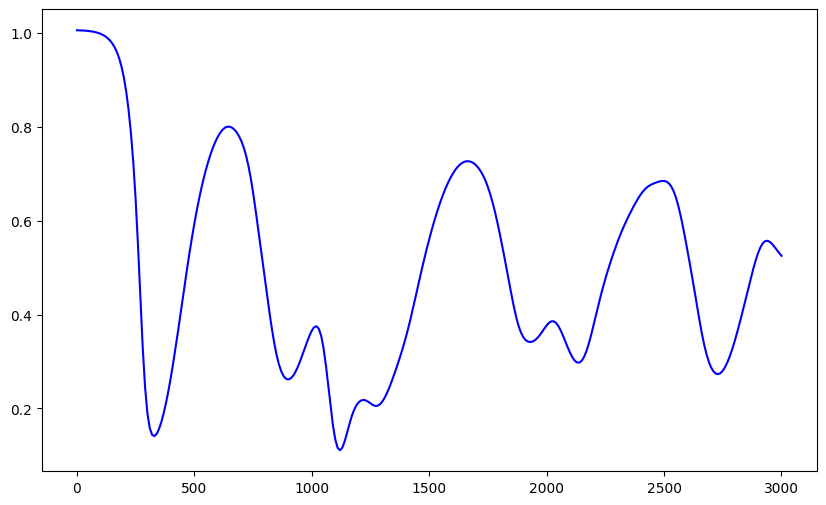

In [69]:
cor_x = 0.3
cor_y = 0.7

times = torch.tensor(np.arange(0, 3001, 10).reshape(-1, 1), dtype=torch.float32, device=device)
times_min, times_max = times.min(), times.max()
x = torch.tensor([cor_x], dtype=torch.float32, device=device).repeat(len(times), 1)
y = torch.tensor([cor_y], dtype=torch.float32, device=device).repeat(len(times), 1)

u_pred = u_nn(torch.cat([normalize(x, x_min, x_max),
                         normalize(y, y_min, y_max),   
                         normalize(times, times_min, times_max)], dim=1))

u_true = u_df.iloc[0, 2:].values.reshape(-1, 1)

# draw plot for u_pred

plt.figure(figsize=(10, 6))
plt.plot(times.cpu().numpy(), u_pred.detach().cpu().numpy(), label=f'Predicted u at ({cor_x})', color='blue')
# plt.plot(times.cpu().numpy(), u_true, label='True u at (0.25, 0.25)', color='red', linestyle='--')
# plt.title(f'Predicted u over time at ({cor_x.item():.2f}, {cor_y.item():.2f})')

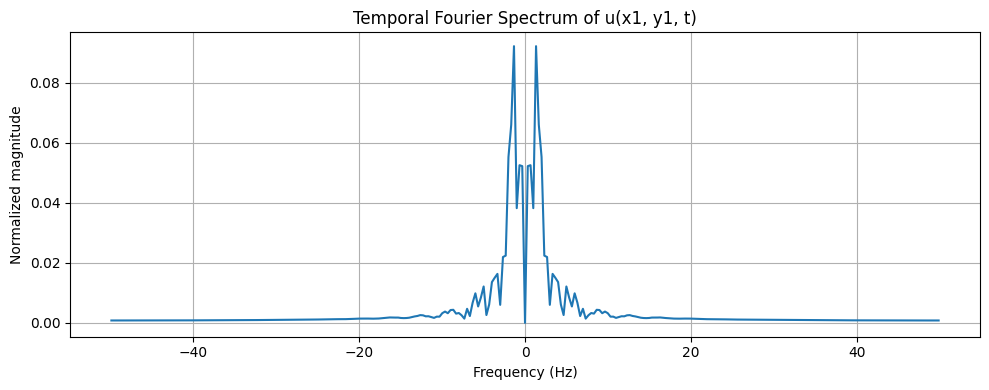

Number of samples: 301
Total duration: 3.0 seconds
Frequency resolution: 0.332226 Hz
Nyquist frequency: 50.000 Hz


In [59]:
import torch
import matplotlib.pyplot as plt

# u_pred: your 301 predicted values at fixed (x1, y1)
u = u_pred.detach().flatten().cpu().to(torch.float64)

dt = 0.01  # seconds
N = u.numel()

# Remove the mean to focus on temporal fluctuations
u_centered = u - u.mean()

# FFT and shifted frequency axis
U = torch.fft.fftshift(torch.fft.fft(u_centered))
freq = torch.fft.fftshift(torch.fft.fftfreq(N, d=dt))

# Magnitude spectrum
magnitude = torch.abs(U) / N

plt.figure(figsize=(10, 4))
plt.plot(freq.numpy(), magnitude.numpy())
plt.xlabel("Frequency (Hz)")
plt.ylabel("Normalized magnitude")
plt.title("Temporal Fourier Spectrum of u(x1, y1, t)")
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Number of samples: {N}")
print(f"Total duration: {(N - 1) * dt} seconds")
print(f"Frequency resolution: {1 / (N * dt):.6f} Hz")
print(f"Nyquist frequency: {1 / (2 * dt):.3f} Hz")

In [60]:
import torch

u = u_pred.detach().flatten().cpu().to(torch.float64)


N = len(u)

# Remove the mean
u_centered = u - u.mean()

# FFT
U = torch.fft.fft(u_centered)
freq = torch.fft.fftfreq(N, d=dt)
magnitude = torch.abs(U) / N

# Consider only positive frequencies, excluding zero
mask = freq > 0
positive_freq = freq[mask]
positive_mag = magnitude[mask]

# Dominant positive frequency
idx = torch.argmax(positive_mag)
f_dom = positive_freq[idx].item()
amp_dom = positive_mag[idx].item()

print(f"Dominant frequency: {f_dom:.6f} Hz")
print(f"Normalized magnitude: {amp_dom:.6g}")
print(f"Characteristic period: {1/f_dom:.2f} seconds")

Dominant frequency: 1.328904 Hz
Normalized magnitude: 0.092134
Characteristic period: 0.75 seconds


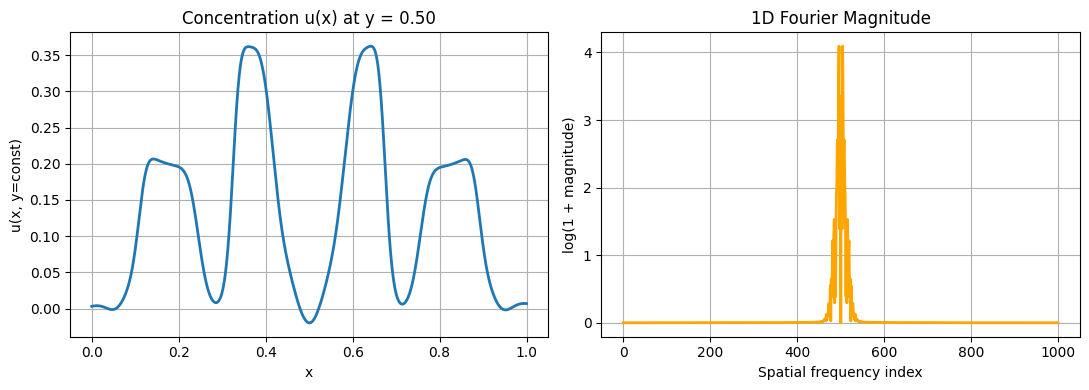

In [95]:
# 1. Choose a constant y value (e.g., the midpoint of y_min and y_max)
y_val = 0.5 * (y_min + y_max)

# 2. Create 1D spatial grid for x and constant y and t
x_line = torch.linspace(x_min, x_max, 1000, device=device).reshape(-1, 1)
y_line = torch.full_like(x_line, fill_value=y_val, device=device)
t_line = torch.full_like(x_line, fill_value=1000.0, device=device)

# 3. Normalize and concatenate inputs for the neural network -> Shape: (1000, 3)
inputs_line = torch.cat(
    [
        normalize(x_line, x_min, x_max),
        normalize(y_line, y_min, y_max),
        normalize(t_line, t_min, t_max),
    ],
    dim=1,
)

# 4. Evaluate network and get 1D concentration profile
u_line = v_nn(inputs_line).detach().cpu().float().squeeze()  # Shape: (1000,)

# 5. Remove mean to focus on spatial variations
u_line_centered = u_line - u_line.mean()

# 6. 1D Fast Fourier Transform
U_line = torch.fft.fftshift(torch.fft.fft(u_line_centered))
spectrum_line = torch.log1p(torch.abs(U_line))

# 7. Plotting the spatial profile and its 1D Fourier spectrum
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(x_line.cpu().numpy(), u_line.numpy(), lw=2)
ax[0].set_title(f"Concentration u(x) at y = {y_val:.2f}")
ax[0].set_xlabel("x")
ax[0].set_ylabel("u(x, y=const)")
ax[0].grid(True)

ax[1].plot(spectrum_line.numpy(), lw=2, color="orange")
ax[1].set_title("1D Fourier Magnitude")
ax[1].set_xlabel("Spatial frequency index")
ax[1].set_ylabel("log(1 + magnitude)")
ax[1].grid(True)

plt.tight_layout()
plt.show()

--- Top Dominant Frequencies ---
1000
Rank 1: Frequency = 4.0000 cycles/unit length | Magnitude = 58.9286
Rank 2: Frequency = -4.0000 cycles/unit length | Magnitude = 58.9286
Rank 3: Frequency = 5.0000 cycles/unit length | Magnitude = 37.3925
Rank 4: Frequency = -5.0000 cycles/unit length | Magnitude = 37.3925


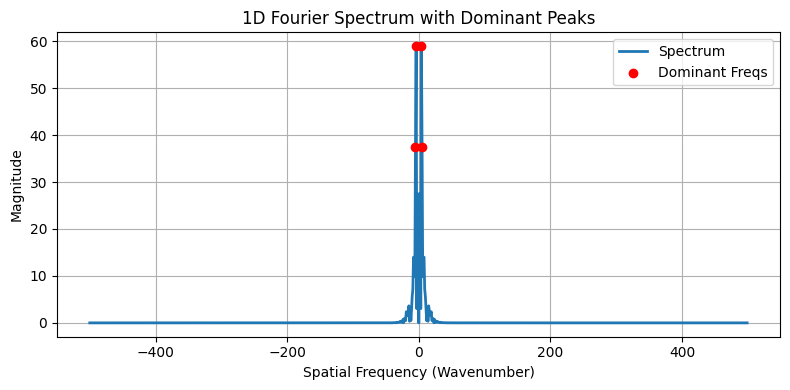

In [ ]:
# 1. Define grid parameters
N = 1000
dx = (x_max - x_min) / N  # Spatial resolution / grid spacing

# 2. Generate the physical frequency bins corresponding to the FFT
freqs = torch.fft.fftfreq(N, d=dx)
freqs_shifted = torch.fft.fftshift(freqs)  # Shift to match fftshift(fft(...))

# 3. Get the raw magnitude (without log) to accurately find physical peaks
magnitude = torch.abs(U_line)  # U_line is your shift-corrected FFT from the previous step

# 4. Find the top K dominant frequencies (e.g., top 3 peaks)
top_k = 4
top_magnitudes, top_indices = torch.topk(magnitude, k=top_k)
dominant_freqs = freqs_shifted[top_indices]

print("--- Top Dominant Frequencies ---")
for i in range(top_k):
    print(f"Rank {i+1}: Frequency = {dominant_freqs[i].item():.4f} cycles/unit length | Magnitude = {top_magnitudes[i].item():.4f}")

# 5. Optional: Plot the spectrum with markers highlighting the dominant frequencies
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(freqs_shifted.cpu().numpy(), magnitude.cpu().numpy(), lw=2, label="Spectrum")
ax.scatter(dominant_freqs.cpu().numpy(), top_magnitudes.cpu().numpy(), color="red", zorder=5, label="Dominant Freqs")

ax.set_title("1D Fourier Spectrum with Dominant Peaks")
ax.set_xlabel("Spatial Frequency (Wavenumber)")
ax.set_ylabel("Magnitude")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
print(freqs_shifted[0])


In [77]:
print(t_grid.shape, x_grid.shape)

torch.Size([100, 1]) torch.Size([100, 1])


## Some Sanity Checks

Are the residuals Low for pre-trained data ?

In [46]:
import math
Du_true_fn = lambda x, y: 2e-5 * (1 + torch.sin(math.pi * x) * torch.sin(math.pi * y))
Dv_true_fn = lambda x, y: 1e-5 * torch.ones_like(x)
Du_zero_fn = lambda x, y: torch.zeros_like(x)
Du_cons_fn = lambda x, y: torch.ones_like(x)*2e-5*(1+4/(torch.pi**2))
# Dv_cons_fn = lambda x, y: torch.ones_like(x)

cases = {"true D": (Du_true_fn, Dv_true_fn),
         "Du = 0": (Du_zero_fn, Dv_true_fn),
         "Du = Du average": (Du_cons_fn, Dv_true_fn),
         "current estimate": (Du_fn, Dv_fn)}

for name, (a, b) in cases.items():
    torch.manual_seed(0)   # same sample points for every case
    div_u, div_v, loss_u, loss_v, L = be_consistency_loss(u_nn, v_nn, a, b, F, k, 20000, dt_be, sigma_u, sigma_v, t_lo=t_lo_be)
    print(f"{name:18s} {L.item():.3e} | div_u {div_u.item():.3e} | div_v {div_v.item():.3e} | loss_u {loss_u.item():.3e} | loss_v {loss_v.item():.3e}")

true D             4.801e-02 | div_u 2.581e-05 | div_v -8.235e-06 | loss_u 1.640e-02 | loss_v 3.161e-02
Du = 0             1.604e-01 | div_u 0.000e+00 | div_v -8.235e-06 | loss_u 1.288e-01 | loss_v 3.161e-02
Du = Du average    5.504e-02 | div_u 3.439e-05 | div_v -8.235e-06 | loss_u 2.343e-02 | loss_v 3.161e-02
current estimate   1.455e-01 | div_u 8.730e-06 | div_v -1.081e-05 | loss_u 7.500e-02 | loss_v 7.046e-02


Does the PDE fit the data itself? (no NN)

In [47]:
from scipy.interpolate import griddata

n_g = int(np.sqrt(len(df)))
gx, gy = np.meshgrid(np.linspace(float(x_min), float(x_max), n_g),
                     np.linspace(float(y_min), float(y_max), n_g), indexing="ij")
h = (float(x_max) - float(x_min)) / (n_g - 1)
pts = df[["x", "y"]].values
inner = (slice(4, -4), slice(4, -4))

def on_grid(name, t):
    return griddata(pts, df[f"{name}_{t}"].values, (gx, gy), method="cubic")

def div_flux_np(D, f):
    fx, fy = np.gradient(f, h, axis=0), np.gradient(f, h, axis=1)
    return np.gradient(D * fx, h, axis=0) + np.gradient(D * fy, h, axis=1)

rms = lambda a: np.sqrt(np.nanmean(a[inner] ** 2))

Du_grid = 2e-5 * (1 + np.sin(np.pi * gx) * np.sin(np.pi * gy))
Dv_grid = 1e-5 * np.ones_like(gx)

for t_chk in [1000, 2000]:
    u0, v0 = on_grid("u", t_chk), on_grid("v", t_chk)
    u_t = (on_grid("u", t_chk + 10) - on_grid("u", t_chk - 10)) / 20.0
    v_t = (on_grid("v", t_chk + 10) - on_grid("v", t_chk - 10)) / 20.0

    diff_u = div_flux_np(Du_grid, u0)
    diff_v = div_flux_np(Dv_grid, v0)
    react_u = -u0 * v0**2 + F * (1 - u0)
    react_v = u0 * v0**2 - (F + k) * v0

    print(f"\nt={t_chk}: rms u_t {rms(u_t):.2e} | diffusion_u {rms(diff_u):.2e} | reaction_u {rms(react_u):.2e}")
    print(f"        rms v_t {rms(v_t):.2e} | diffusion_v {rms(diff_v):.2e} | reaction_v {rms(react_v):.2e}")
    for s in [0, 0.5, 1.0, 1.5, 2.0]:
        res_u = u_t - s * diff_u - react_u
        res_v = v_t - s * diff_v - react_v
        print(f"  s={s:3.1f}  residual rms  u: {rms(res_u):.2e}   v: {rms(res_v):.2e}")


t=1000: rms u_t 3.21e-03 | diffusion_u 5.44e-03 | reaction_u 6.96e-03
        rms v_t 2.11e-03 | diffusion_v 2.04e-03 | reaction_v 3.32e-03
  s=0.0  residual rms  u: 5.96e-03   v: 2.46e-03
  s=0.5  residual rms  u: 3.28e-03   v: 1.48e-03
  s=1.0  residual rms  u: 8.62e-04   v: 6.00e-04
  s=1.5  residual rms  u: 2.36e-03   v: 7.84e-04
  s=2.0  residual rms  u: 5.02e-03   v: 1.72e-03

t=2000: rms u_t 3.08e-03 | diffusion_u 5.46e-03 | reaction_u 6.50e-03
        rms v_t 1.86e-03 | diffusion_v 2.14e-03 | reaction_v 2.94e-03
  s=0.0  residual rms  u: 5.94e-03   v: 2.48e-03
  s=0.5  residual rms  u: 3.24e-03   v: 1.44e-03
  s=1.0  residual rms  u: 7.86e-04   v: 5.27e-04
  s=1.5  residual rms  u: 2.37e-03   v: 8.80e-04
  s=2.0  residual rms  u: 5.05e-03   v: 1.89e-03


In [75]:
@torch.no_grad()
def heldout_mse(name, net, t):
    xs = torch.tensor(df["x"].values, dtype=torch.float32, device=device).reshape(-1, 1)
    ys = torch.tensor(df["y"].values, dtype=torch.float32, device=device).reshape(-1, 1)
    ts = torch.full_like(xs, float(t))
    X = torch.cat([normalize(xs, x_min, x_max), normalize(ys, y_min, y_max),
                   normalize(ts, t_min, t_max)], dim=1)
    pred = net(X).cpu().numpy().ravel()
    true = df[f"{name}_{t}"].values
    return np.mean((pred - true) ** 2), np.var(true)

for t in [1000, 2000, 3000]:
    for name, net in [("u", u_nn), ("v", v_nn)]:
        mse, var = heldout_mse(name, net, t)
        print(f"t={t} {name}: held-out MSE {mse:.2e} | var {var:.2e} | ratio {mse/var:.3f}")

t=1000 u: held-out MSE 1.72e-01 | var 6.30e-02 | ratio 2.736
t=1000 v: held-out MSE 2.57e-02 | var 1.13e-02 | ratio 2.283
t=2000 u: held-out MSE 1.00e-01 | var 5.74e-02 | ratio 1.742
t=2000 v: held-out MSE 2.08e-02 | var 1.08e-02 | ratio 1.921
t=3000 u: held-out MSE 2.84e-02 | var 4.18e-02 | ratio 0.678
t=3000 v: held-out MSE 1.06e-02 | var 9.69e-03 | ratio 1.092


In [76]:
for s in [0, 0.5, 1.0, 1.5, 2.0]:
    torch.manual_seed(0)
    Du_s = lambda x, y, s=s: s * Du_true_fn(x, y)
    Dv_s = lambda x, y, s=s: s * Dv_true_fn(x, y)
    div_u, div_v, L = be_consistency_loss(u_nn, v_nn, Du_s, Dv_s, F, k, 20000, dt_be,
                            sigma_u, sigma_v, t_lo=t_lo_be)
    print(f"s={s:3.1f}  loss {L.item():.3e}")

s=0.0  loss 2.879e-01
s=0.5  loss 8.702e-02
s=1.0  loss 4.952e-02
s=1.5  loss 1.754e-01
s=2.0  loss 4.648e-01


## Visually Checking data fit

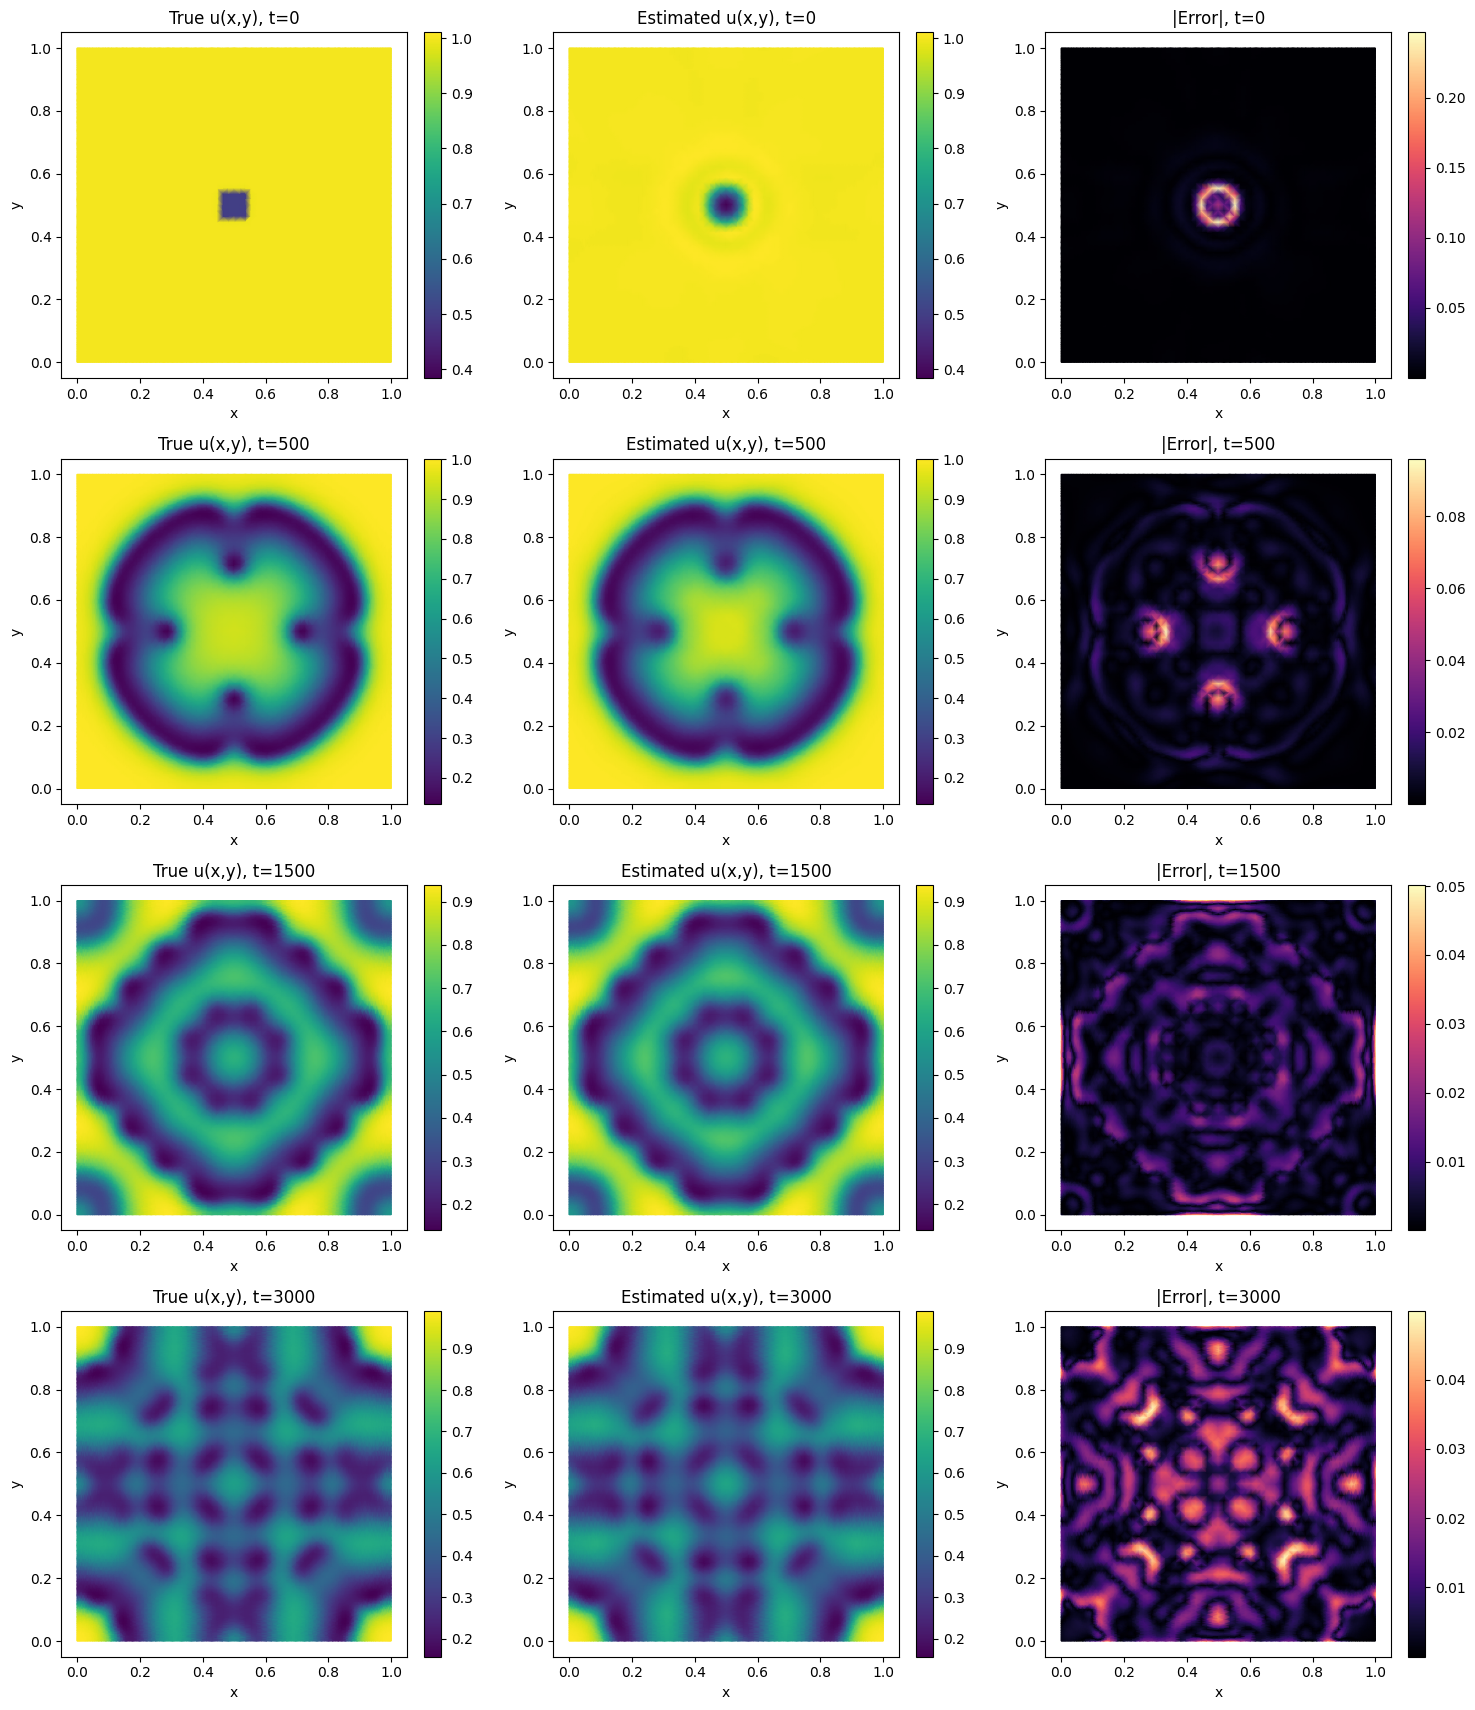

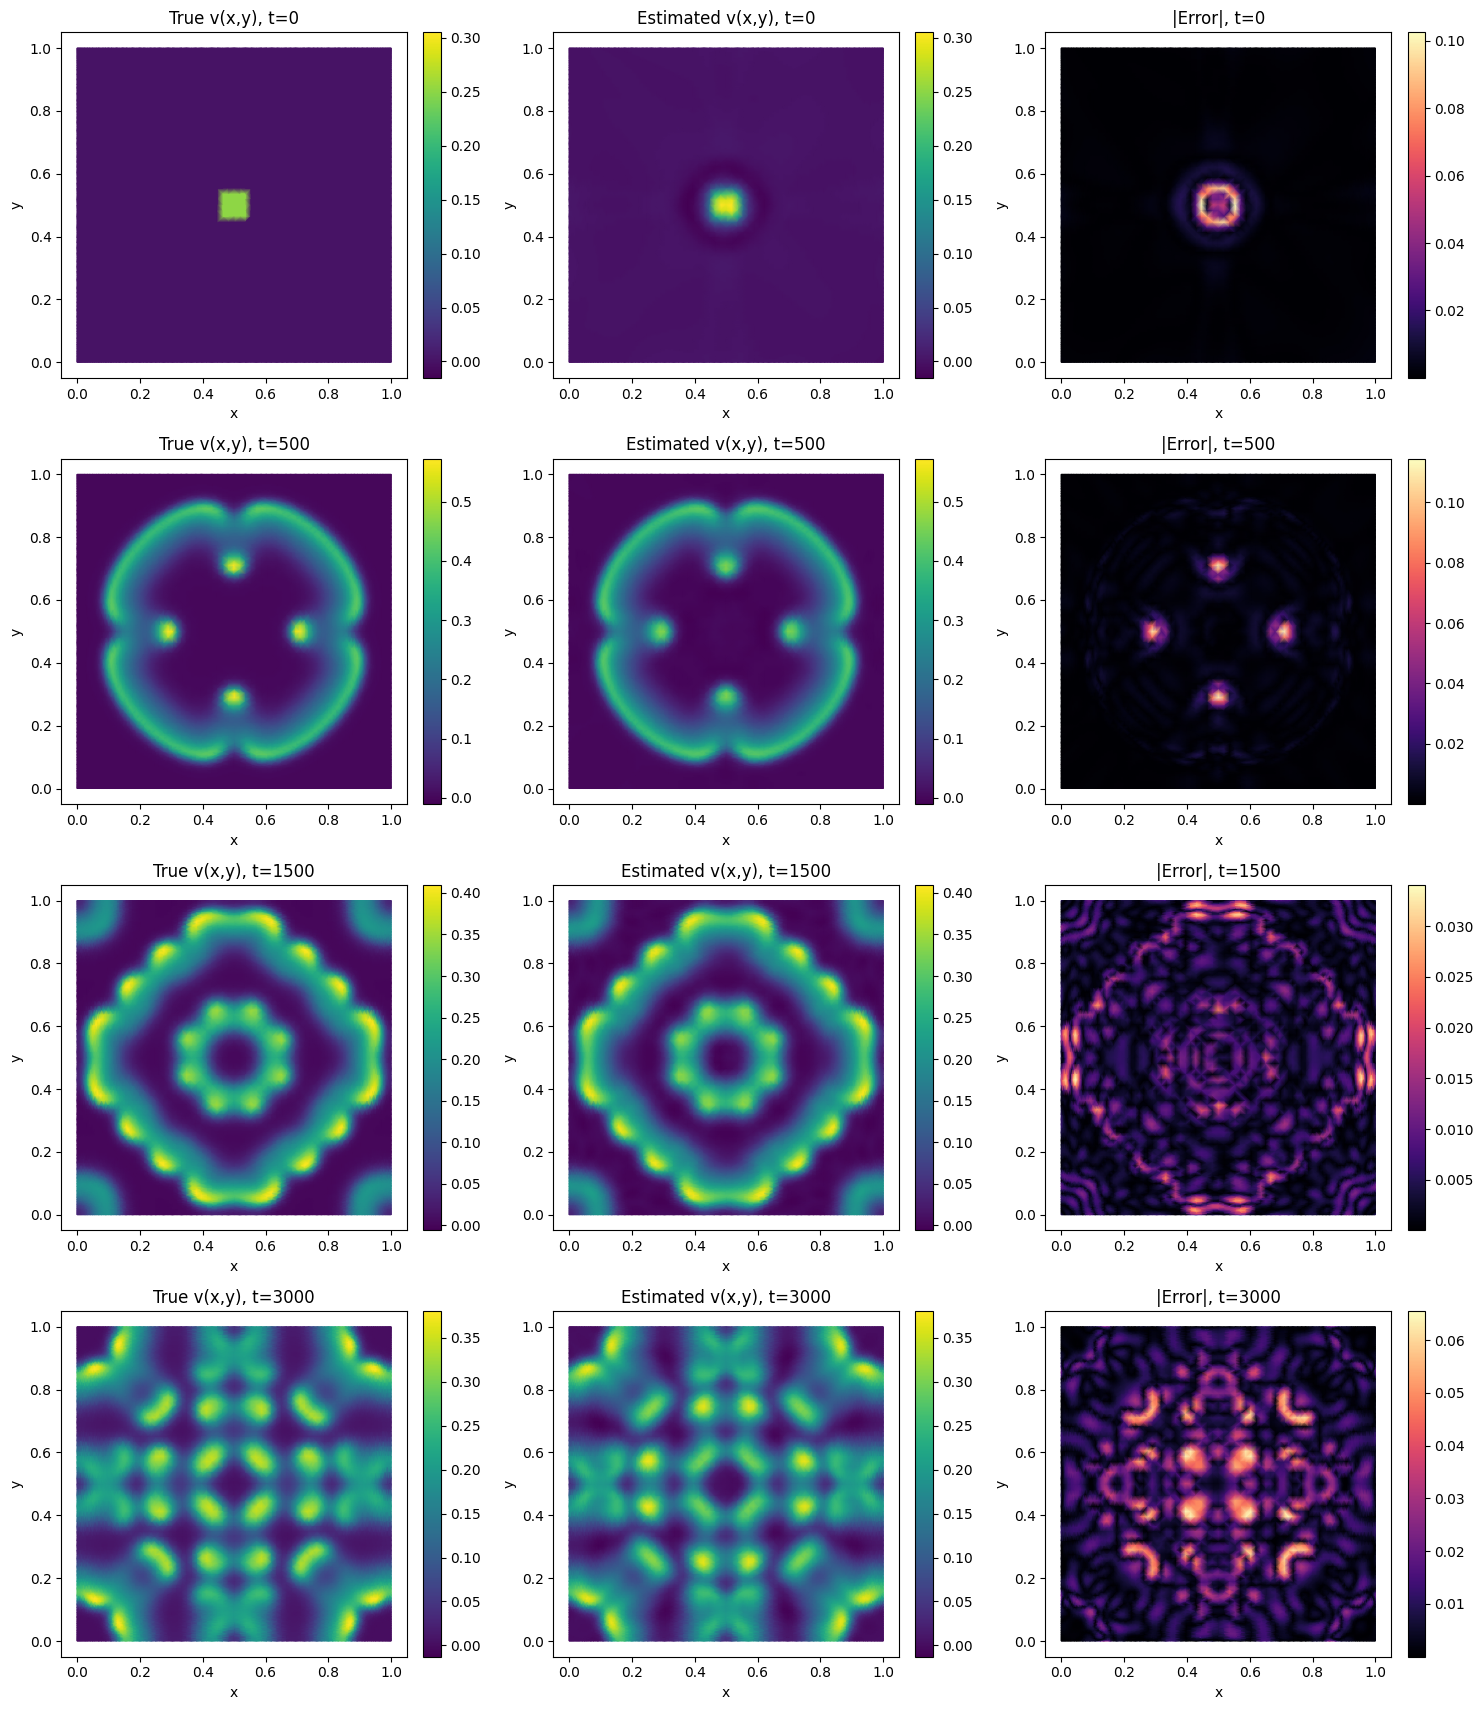

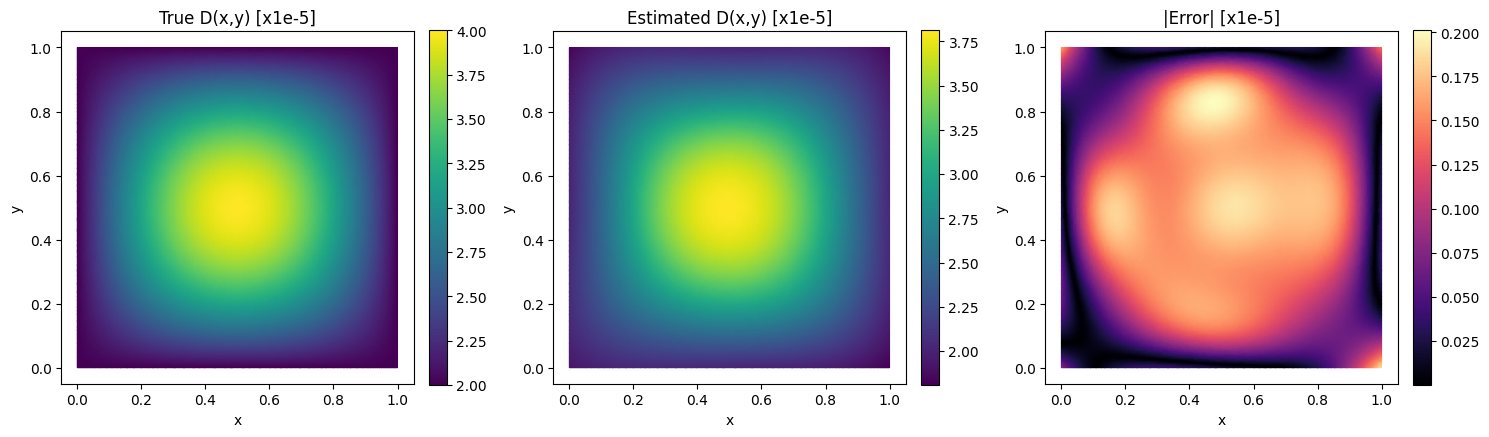

In [125]:
import matplotlib.tri as mtri

# ---------------------------------------------------------
# Settings
# ---------------------------------------------------------
plot_times = [0, 500, 1500, 3000]   # multiples of 10 in [0, 3000]

# True diffusion coefficients
D_true_fn = lambda x, y: 2e-5 * (1 + np.sin(np.pi * x) * np.sin(np.pi * y))
Dv_true = 1e-5

# ---------------------------------------------------------
# Mesh from the data
# ---------------------------------------------------------
x_all = df["x"].values
y_all = df["y"].values
triang = mtri.Triangulation(x_all, y_all)

x_t = torch.tensor(x_all, dtype=torch.float32, device=device).reshape(-1, 1)
y_t = torch.tensor(y_all, dtype=torch.float32, device=device).reshape(-1, 1)

# ---------------------------------------------------------
# Predictions
# ---------------------------------------------------------
@torch.no_grad()
def predict_uv(t_val):
    t_t = torch.full_like(x_t, float(t_val))
    X = torch.cat([
        normalize(x_t, x_min, x_max),
        normalize(y_t, y_min, y_max),
        normalize(t_t, t_min, t_max)
    ], dim=1)
    return u_nn(X).cpu().numpy().ravel(), v_nn(X).cpu().numpy().ravel()

@torch.no_grad()
def predict_D():
    X = torch.cat([
        normalize(x_t, x_min, x_max),
        normalize(y_t, y_min, y_max)
    ], dim=1)
    return Du_nn(X).cpu().numpy().ravel()

# ---------------------------------------------------------
# Heatmap helper
# ---------------------------------------------------------
def heat(ax, values, title, vmin=None, vmax=None, cmap="viridis"):
    cf = ax.tripcolor(triang, values, shading="gouraud", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    plt.colorbar(cf, ax=ax, fraction=0.046, pad=0.04)

# ---------------------------------------------------------
# u and v: true | estimated | |error|, one row per time
# ---------------------------------------------------------
preds = {t: predict_uv(t) for t in plot_times}

for field, idx in [("u", 0), ("v", 1)]:
    n = len(plot_times)
    fig, axes = plt.subplots(n, 3, figsize=(15, 4.3 * n), squeeze=False)

    for i, t in enumerate(plot_times):
        true = df[f"{field}_{t}"].values
        pred = preds[t][idx]
        err = np.abs(pred - true)

        vmin = min(true.min(), pred.min())
        vmax = max(true.max(), pred.max())

        heat(axes[i, 0], true, f"True {field}(x,y), t={t}", vmin, vmax)
        heat(axes[i, 1], pred, f"Estimated {field}(x,y), t={t}", vmin, vmax)
        heat(axes[i, 2], err,  f"|Error|, t={t}", cmap="magma")

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# D(x,y): true | estimated | |error|
# ---------------------------------------------------------
D_est = predict_D()
D_true = D_true_fn(x_all, y_all)

share_scale = False   # set True once the estimate is in the right range

u0 = 1e-5   # plot in units of 1e-5
if share_scale:
    vmin = min(D_true.min(), D_est.min()) / u0
    vmax = max(D_true.max(), D_est.max()) / u0
    lim_true = lim_est = (vmin, vmax)
else:
    lim_true = (D_true.min() / u0, D_true.max() / u0)
    lim_est  = (None, None)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
heat(axes[0], D_true / u0, "True D(x,y) [x1e-5]", *lim_true)
heat(axes[1], D_est / u0,  "Estimated D(x,y) [x1e-5]", *lim_est)
heat(axes[2], np.abs(D_est - D_true) / u0, "|Error| [x1e-5]", cmap="magma")
plt.tight_layout()
plt.show()

Plot D_u in 3D

In [48]:
def plot_Du_3D(x, y, D_true, D_pred, scale=1e-5):

    D_true_scaled = D_true / scale
    D_pred_scaled = D_pred / scale
    error_scaled = np.abs(D_pred - D_true) / scale

    fig = plt.figure(figsize=(19, 6))

    # ---------------------------------------------------------
    # True
    # ---------------------------------------------------------
    ax1 = fig.add_subplot(1, 3, 1, projection="3d")

    surf1 = ax1.plot_trisurf(
        x, y, D_true_scaled,
        cmap="viridis",
        linewidth=0,
        antialiased=True
    )

    ax1.set_title("True $D_u(x,y)$")
    ax1.set_xlabel("x")
    ax1.set_ylabel("y")
    ax1.set_zlabel(r"$D_u\,[10^{-5}]$")

    # ---------------------------------------------------------
    # Predicted
    # ---------------------------------------------------------
    ax2 = fig.add_subplot(1, 3, 2, projection="3d")

    surf2 = ax2.plot_trisurf(
        x, y, D_pred_scaled,
        cmap="viridis",
        linewidth=0,
        antialiased=True
    )

    ax2.set_title("Predicted $D_u(x,y)$")
    ax2.set_xlabel("x")
    ax2.set_ylabel("y")
    ax2.set_zlabel(r"$D_u\,[10^{-5}]$")

    # ---------------------------------------------------------
    # Absolute error
    # ---------------------------------------------------------
    ax3 = fig.add_subplot(1, 3, 3, projection="3d")

    surf3 = ax3.plot_trisurf(
        x, y, error_scaled,
        cmap="magma",
        linewidth=0,
        antialiased=True
    )

    ax3.set_title(r"$|D_u^{pred}-D_u^{true}|$")
    ax3.set_xlabel("x")
    ax3.set_ylabel("y")
    ax3.set_zlabel(r"Error $[10^{-5}]$")

    fig.colorbar(surf1, ax=ax1, shrink=0.6, pad=0.08)
    fig.colorbar(surf2, ax=ax2, shrink=0.6, pad=0.08)
    fig.colorbar(surf3, ax=ax3, shrink=0.6, pad=0.08)

    plt.tight_layout()
    plt.show()

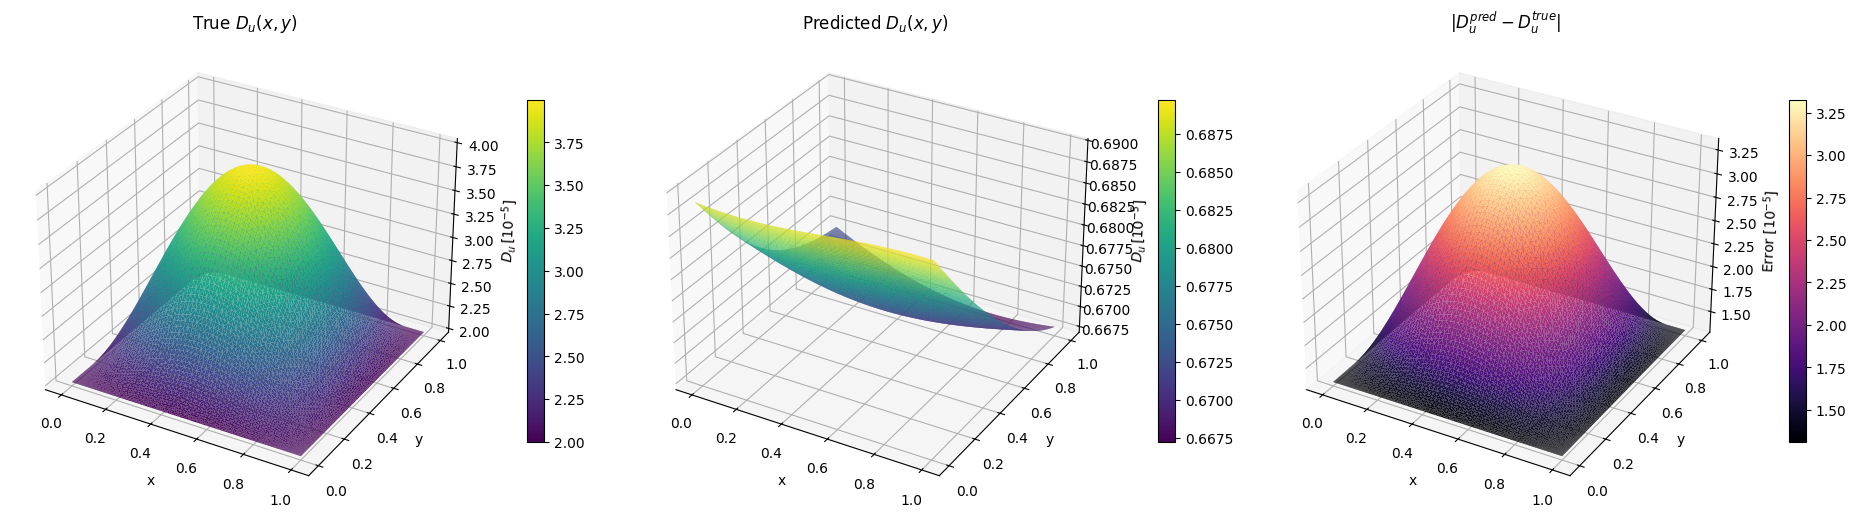

In [49]:
D_est = predict_D()
D_true = D_true_fn(x_all, y_all)

plot_Du_3D(x_all, y_all, D_true, D_est)

## Main Training Loop

## Specify Hyper parameteres

In [50]:
num_epochs = 4000

optimizer = torch.optim.Adam(
    list(u_nn.parameters()) +
    list(v_nn.parameters()) +
    list(Du_nn.parameters()) +
    list(Dv_nn.parameters()),
    lr=1e-3
)

## Stage A - Training Only for Du and Dv with weights for u and v frozen

### Specify Hyperparams

In [ ]:
# freeze the pretrained u, v networks
for p in list(u_nn.parameters()) + list(v_nn.parameters()):
    p.requires_grad_(False)

n_D_steps = 4000
optimizer_D = torch.optim.Adam(list(Du_nn.parameters()) + list(Dv_nn.parameters()), lr=2e-4)
sched_D = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_D, T_max=n_D_steps, eta_min=1e-5)

### Training

In [51]:
stage_a_con_loss = []

In [ ]:
for step in range(n_D_steps):
    div_u, div_v, loss_u,loss_v,L = be_consistency_loss(u_nn, v_nn, Du_fn, Dv_fn, F, k, 10000, dt_be,
                            sigma_u, sigma_v, t_lo=t_lo_be)
    stage_a_con_loss.append(L.item())
    optimizer_D.zero_grad()
    L.backward()
    optimizer_D.step()
    sched_D.step()

    if (step + 1) % 1 == 0 or step == 0:
       print(f"step {step+1}/{n_D_steps} | loss {L.item():.3e} | Dv {Dv_nn.value().item():.3e} | loss_u {loss_u.item():.3e} | loss_v {loss_v.item():.3e}")



# n_D_steps = 4000

# optimizer_D = torch.optim.Adam(
#     list(Du_nn.parameters()) + list(Dv_nn.parameters()),
#     lr=2e-4
# )

# sched_D = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer_D,
#     T_max=n_D_steps,
#     eta_min=1e-5
# )

# for step in range(n_D_steps):

#     # Turn on adaptive sampling after 500 steps
#     use_adaptive = step >= 500

#     div_u, div_v, loss_u, loss_v, L = be_consistency_loss(
#         u_nn, v_nn,
#         Du_fn, Dv_fn,
#         F, k,
#         10000,
#         dt_be,
#         sigma_u, sigma_v,
#         t_lo=t_lo_be,

#         adaptive=use_adaptive,
#         N_candidates=50000,
#         adaptive_fraction=0.4,
#         alpha=0.5
#     )

#     stage_a_con_loss.append(L.item())

#     optimizer_D.zero_grad()
#     L.backward()

#     optimizer_D.step()
#     sched_D.step()

#     if (step + 1) % 200 == 0:
#         print(
#             f"step {step+1}/{n_D_steps} | "
#             f"loss {L.item():.3e} | "
#             f"Dv {Dv_nn.value().item():.3e} | "
#             f"loss_u {loss_u.item():.3e} | "
#             f"loss_v {loss_v.item():.3e}"
#         )

step 1/3 | loss 3.526e-01 | Dv 1.313e-05 | loss_u 3.001e-01 | loss_v 5.247e-02
step 2/3 | loss 3.559e-01 | Dv 1.313e-05 | loss_u 3.048e-01 | loss_v 5.106e-02
step 3/3 | loss 3.429e-01 | Dv 1.313e-05 | loss_u 2.910e-01 | loss_v 5.189e-02


### Plotting Loss for stage A

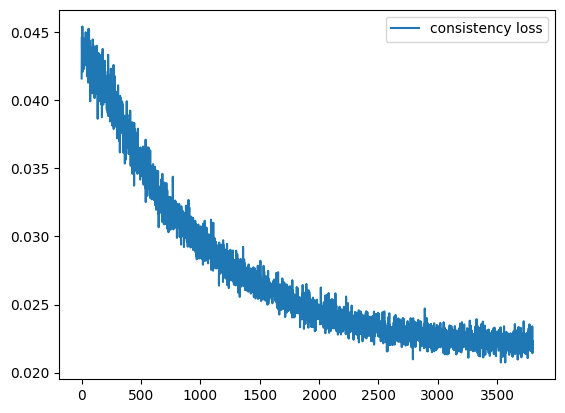

In [78]:
plt.plot([epoch for epoch in range(len(stage_a_con_loss[200:]))], stage_a_con_loss[200:], label="consistency loss")
plt.legend()

### Calculating error for Du(x,y)

In [122]:
# Evaluate on all mesh points
x_all = torch.tensor(df["x"].values, dtype=torch.float32, device=device).reshape(-1, 1)
y_all = torch.tensor(df["y"].values, dtype=torch.float32, device=device).reshape(-1, 1)

with torch.no_grad():
    Du_pred = Du_nn(torch.cat([normalize(x_all, x_min, x_max),
                               normalize(y_all, y_min, y_max)], dim=1)).cpu().numpy().ravel()

x_np, y_np = df["x"].values, df["y"].values
Du_true = 2e-5 * (1 + np.sin(np.pi * x_np) * np.sin(np.pi * y_np))

# 1. MSE (absolute units)
mse = np.mean((Du_pred - Du_true) ** 2)
rmse = np.sqrt(mse)

# 2. Relative L2 error (RMSE as a fraction of the true D's RMS)
rel_l2 = np.sqrt(np.sum((Du_pred - Du_true) ** 2) / np.sum(Du_true ** 2))

# 3. The paper's error (Eq. 7): normalized by the variation of D_true around its mean,
#    so it is not flattered by a large constant offset in D
L_paper = np.sqrt(np.mean((Du_true - Du_pred) ** 2) / np.mean((Du_true - Du_true.mean()) ** 2))

print(f"MSE            : {mse:.3e}")
print(f"RMSE           : {rmse:.3e}  ({rmse/1e-5:.3f} x1e-5)")
print(f"Relative L2    : {rel_l2*100:.2f}%")
print(f"Paper error L  : {L_paper*100:.2f}%")
print(f"Mean Du pred / true: {Du_pred.mean():.3e} / {Du_true.mean():.3e}")

MSE            : 4.250e-13
RMSE           : 6.519e-07  (0.065 x1e-5)
Relative L2    : 2.61%
Paper error L  : 12.80%
Mean Du pred / true: 2.457e-05 / 2.440e-05


In [121]:
Dv_est, Dv_true = Dv_nn.value().item(), 1e-5
print(f"Dv: {Dv_est:.3e} vs {Dv_true:.3e} | relative error {abs(Dv_est-Dv_true)/Dv_true*100:.2f}%")

Dv: 1.048e-05 vs 1.000e-05 | relative error 4.84%


## Stage B - Training Du, Dv, u and v all at once

In [131]:
# ---------------------------------------------------------
# 0. Unfreeze u, v (they were frozen in Stage A) and switch to train mode
# ---------------------------------------------------------
for p in list(u_nn.parameters()) + list(v_nn.parameters()):
    p.requires_grad_(True)
for m in (u_nn, v_nn, Du_nn, Dv_nn):
    m.train()

# ---------------------------------------------------------
# 1. Settings
# ---------------------------------------------------------
n_B_steps = 350
data_bs = 8192            # data points per step
N_be = 10000              # consistency-loss points per step
lambda_data = 1.0
lambda_pde_max = 1.0      # tune this: lower if the data loss rises, higher if D stalls
ramp_steps = 100        # PDE weight rises linearly from 0 to lambda_pde_max

uv_params = list(u_nn.parameters()) + list(v_nn.parameters())
D_params = list(Du_nn.parameters()) + list(Dv_nn.parameters())

optimizer_B = torch.optim.Adam([
    {"params": uv_params, "lr": 5e-4},     # small: don't destroy the pre-trained fit
    {"params": D_params,  "lr": 5e-4},
])
sched_B = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_B, T_max=n_B_steps, eta_min=1e-6)

# ---------------------------------------------------------
# 2. Data loss, normalized by sigma (same units as the consistency loss)
# ---------------------------------------------------------
def data_loss_norm(idx):
    Xu_b, Xv_b = X_u[idx], X_v[idx]
    def norm_in(X):
        return torch.cat([normalize(X[:, 0:1], x_min, x_max),
                          normalize(X[:, 1:2], y_min, y_max),
                          normalize(X[:, 2:3], t_min, t_max)], dim=1)
    lu = torch.mean(((u_nn(norm_in(Xu_b)) - U_true[idx]) / sigma_u) ** 2)
    lv = torch.mean(((v_nn(norm_in(Xv_b)) - V_true[idx]) / sigma_v) ** 2)
    return lu + lv

# ---------------------------------------------------------
# 3. Monitoring of D error (uses your known true D, for monitoring only)
# ---------------------------------------------------------
mon_idx = np.random.RandomState(0).choice(len(df), 5000, replace=False)
x_mon = torch.tensor(df["x"].values[mon_idx], dtype=torch.float32, device=device).reshape(-1, 1)
y_mon = torch.tensor(df["y"].values[mon_idx], dtype=torch.float32, device=device).reshape(-1, 1)
Du_true_mon = (2e-5 * (1 + torch.sin(np.pi * x_mon) * torch.sin(np.pi * y_mon))).cpu().numpy().ravel()

@torch.no_grad()
def du_errors():
    pred = Du_nn(torch.cat([normalize(x_mon, x_min, x_max),
                            normalize(y_mon, y_min, y_max)], dim=1)).cpu().numpy().ravel()
    mse = np.mean((pred - Du_true_mon) ** 2)
    L_paper = np.sqrt(mse / np.mean((Du_true_mon - Du_true_mon.mean()) ** 2))
    return mse, L_paper

# ---------------------------------------------------------
# 4. Training loop
# ---------------------------------------------------------
hist = {"data": [], "pde": [], "Du_L": []}
N_rows = X_u.shape[0]

for step in range(n_B_steps):

    w_pde = lambda_pde_max * min(1.0, (step + 1) / ramp_steps)

    idx = torch.randint(0, N_rows, (data_bs,), device=device)
    L_data = data_loss_norm(idx)

    div_u, div_v, loss_u, loss_v, L_pde = be_consistency_loss(u_nn, v_nn, Du_fn, Dv_fn, F, k,
                                N_be, dt_be, sigma_u, sigma_v, t_lo=t_lo_be)

    L = lambda_data * L_data + w_pde * L_pde

    optimizer_B.zero_grad()
    L.backward()
    torch.nn.utils.clip_grad_norm_(uv_params + D_params, 1.0)
    optimizer_B.step()
    sched_B.step()

    if (step + 1) % 5 == 0:
        mse_D, L_D = du_errors()
        hist["data"].append(L_data.item()); hist["pde"].append(L_pde.item()); hist["Du_L"].append(L_D)
        if (step + 1) % 5 == 0:
            print(f"step {step+1}/{n_B_steps} | data {L_data.item():.3e} | pde {L_pde.item():.3e} "
                  f"| w_pde {w_pde:.2f} | Du MSE {mse_D:.2e} | Du L {L_D*100:.1f}% "
                  f"| Dv {Dv_nn.value().item():.3e}")



step 5/350 | data 5.925e-02 | pde 4.050e-01 | w_pde 0.05 | Du MSE 6.75e-13 | Du L 16.2% | Dv 1.048e-05
step 10/350 | data 1.742e-02 | pde 1.679e-01 | w_pde 0.10 | Du MSE 1.77e-12 | Du L 26.3% | Dv 1.047e-05
step 15/350 | data 8.993e-03 | pde 5.625e-02 | w_pde 0.15 | Du MSE 8.68e-13 | Du L 18.4% | Dv 1.047e-05
step 20/350 | data 7.195e-03 | pde 4.430e-02 | w_pde 0.20 | Du MSE 4.45e-13 | Du L 13.2% | Dv 1.046e-05
step 25/350 | data 7.038e-03 | pde 3.721e-02 | w_pde 0.25 | Du MSE 4.57e-13 | Du L 13.4% | Dv 1.046e-05
step 30/350 | data 8.594e-03 | pde 5.030e-02 | w_pde 0.30 | Du MSE 5.99e-13 | Du L 15.3% | Dv 1.045e-05
step 35/350 | data 6.407e-03 | pde 3.787e-02 | w_pde 0.35 | Du MSE 5.28e-13 | Du L 14.4% | Dv 1.045e-05
step 40/350 | data 5.576e-03 | pde 3.233e-02 | w_pde 0.40 | Du MSE 4.45e-13 | Du L 13.2% | Dv 1.045e-05
step 45/350 | data 5.127e-03 | pde 3.292e-02 | w_pde 0.45 | Du MSE 4.42e-13 | Du L 13.1% | Dv 1.044e-05
step 50/350 | data 5.223e-03 | pde 2.633e-02 | w_pde 0.50 | Du MS

# Saving fully trained models

Specify the stage

In [ ]:
stage = "A"

In [ ]:
import os
# from google.colab import drive
# drive.mount("/content/drive")   # skip if already mounted

save_dir = f"/content/drive/MyDrive/gray_scott/checkpoints_{param}/trained_stage_{stage}"
os.makedirs(save_dir, exist_ok=True)
stageB_path = os.path.join(save_dir, f"uv_{n_data}_pts_stage_{stage}.pt")

torch.save({
    "u_nn": u_nn.state_dict(),
    "v_nn": v_nn.state_dict(),
    "Du_nn": Du_nn.state_dict(),
    "Dv_nn": Dv_nn.state_dict(),      # contains Dv_raw
    "optimizer_D": optimizer_D.state_dict(),
    "sched_D": sched_D.state_dict(),
    "step": step + 1,                 # last finished Stage B step
    "dt_be": dt_be,
    "t_lo_be": t_lo_be,
    "sigma_u": sigma_u,
    "sigma_v": sigma_v,
    "bounds": dict(x_min=float(x_min), x_max=float(x_max),
                   y_min=float(y_min), y_max=float(y_max),
                   t_min=float(t_min), t_max=float(t_max)),
}, stageB_path)

print("Saved Stage B checkpoint to", stageB_path)

Saved Stage B checkpoint to /content/drive/MyDrive/gray_scott/checkpoints_1/trained_stage_B/uv_10000_pts_stage_b_special.pt


# Loading fully trained models

In [122]:
stage = "b"

In [123]:
# from google.colab import drive
# drive.mount("/content/drive")   # skip if already mounted

stageA_path = f"/content/drive/MyDrive/gray_scott/checkpoints_{param}/trained_stage_B/uv_{n_data}_pts_stage_{stage}.pt"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ckpt = torch.load(stageA_path, map_location=device)

# Check that the normalization bounds match
current = dict(x_min=float(x_min), x_max=float(x_max),
               y_min=float(y_min), y_max=float(y_max),
               t_min=float(t_min), t_max=float(t_max))
assert all(abs(ckpt["bounds"][k_] - current[k_]) < 1e-9 for k_ in current), \
    f"Bounds mismatch! saved={ckpt['bounds']} current={current}"

# Build the networks (same architecture as when saved)
u_nn  = u_net().to(device)          # or ScaledMLP().to(device) if you use that class
v_nn  = v_net().to(device)          # or ScaledMLP().to(device)
Du_nn = Du_net().to(device)
Dv_nn = Dv_net().to(device)

u_nn.load_state_dict(ckpt["u_nn"])
v_nn.load_state_dict(ckpt["v_nn"])
Du_nn.load_state_dict(ckpt["Du_nn"])
Dv_nn.load_state_dict(ckpt["Dv_nn"])

# Re-create the D function wrappers around the loaded networks
Du_fn, Dv_fn = make_D_fns(Du_nn, Dv_nn)

# Restore the loss settings used in Stage A
dt_be, t_lo_be = ckpt["dt_be"], ckpt["t_lo_be"]
sigma_u, sigma_v = ckpt["sigma_u"], ckpt["sigma_v"]

# Freeze u, v (as in Stage A) and switch to eval mode for inference
for p in list(u_nn.parameters()) + list(v_nn.parameters()):
    p.requires_grad_(False)
for m in (u_nn, v_nn, Du_nn, Dv_nn):
    m.eval()

print(f"Loaded Stage {stage} checkpoint. Last step:", ckpt["step"])

Loaded Stage b checkpoint. Last step: 150
